# 07 - Error analysis: where the errors are and why

Self-contained notebook that only reads results of the earlier notebooks (`data/corners.csv`, `data/gate_ml.csv`, `data/gate_devices.csv`, `data/circuit_ml.csv`) and no simulator. It answers the question of the project text: *where do the largest errors occur (which gate, input combination or corner conditions, for example high temperature or low vth0) and why?* Errors are relative errors `(ML - SPICE) / SPICE` of the leakage; "median" and "95th percentile" are of their absolute value, "bias" is the mean signed error.

## 1. Data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR, RESULT_DIR = ROOT / "data", ROOT / "results"
KEY = ["gate", "pattern", "corner"]

corners = pd.read_csv(DATA_DIR / "corners.csv")
gate = pd.read_csv(DATA_DIR / "gate_ml.csv", dtype={"pattern": str}).merge(corners.drop(columns=["vdd", "temp"]), on="corner")
dev = pd.read_csv(DATA_DIR / "gate_devices.csv", dtype={"pattern": str})
circ = pd.read_csv(DATA_DIR / "circuit_ml.csv").merge(corners.drop(columns=["vdd", "temp"]), on="corner")
gate["p_vth0_mag"], circ["p_vth0_mag"] = gate["p_vth0"].abs(), circ["p_vth0"].abs()
print("gate-level points:", len(gate), "| transistor instances:", len(dev), "| circuit points:", len(circ))

gate-level points: 3600 | transistor instances: 16800 | circuit points: 25600


## 2. Gate level: which gates and input patterns
The gate results table of notebook 05, ranked by the median error (all 200 corners per case). The bias shows the direction of the error.

In [2]:
def stats(d, err="err"):
    a = d[err].abs()
    return pd.Series({"n": len(d), "bias [%]": d[err].mean() * 100, "median [%]": a.median() * 100, "95th pct [%]": a.quantile(0.95) * 100, "mean [%]": a.mean() * 100})


by_case = gate.groupby(["gate", "pattern"], sort=False).apply(stats, include_groups=False).sort_values("median [%]", ascending=False)
by_gate = gate.groupby("gate", sort=False).apply(stats, include_groups=False)
by_case.to_csv(RESULT_DIR / "gate_error_by_case.csv")
by_gate.to_csv(RESULT_DIR / "gate_error_by_gate.csv")
print("by gate type:")
display(by_gate.round(2))
print("by gate and input pattern, largest median error first:")
by_case.round(2)

by gate type:


,n,bias [%],median [%],95th pct [%],mean [%]
gate,,,,,
inv,400.0,-0.01,0.54,2.23,0.78
nand2,800.0,0.30,0.46,2.01,0.66
nor2,800.0,0.03,0.64,2.21,0.83
and2,800.0,-0.21,0.68,2.90,0.96
or2,800.0,-0.50,0.59,2.50,0.90


by gate and input pattern, largest median error first:


,,n,bias [%],median [%],95th pct [%],mean [%]
gate,pattern,,,,,
and2,01,200.0,-0.93,0.90,3.63,1.29
or2,00,200.0,-0.93,0.89,3.81,1.27
nor2,01,200.0,0.45,0.79,2.85,1.04
or2,01,200.0,-0.24,0.71,2.83,1.01
nor2,11,200.0,0.10,0.69,2.17,0.83
and2,11,200.0,-0.28,0.66,2.62,0.86
nor2,10,200.0,-0.03,0.64,1.91,0.77
nand2,11,200.0,0.35,0.60,2.50,0.85
inv,1,200.0,0.36,0.60,2.58,0.87


## 3. Gate level: which corner conditions
Median and 95th percentile of the absolute error, and the bias, in bins of temperature, VDD and the process parameters of the corner (all 18 cases pooled; the bins of VDD and of the process parameters are terciles of the 200 corners; for the PMOS `vth0` the magnitude is used, so "low" means a low threshold).

In [3]:
FACTORS = [("temp", "temperature [degC]", [-40, -12.5, 15, 42.5, 70, 97.5, 125]), ("vdd", "VDD [V]", 3), ("n_vth0", "NMOS vth0 [V]", 3), ("p_vth0_mag", "PMOS |vth0| [V]", 3),
           ("n_toxe", "NMOS toxe [m]", 3), ("p_toxe", "PMOS toxe [m]", 3)]


def binned(df, col, bins, err="err"):
    cut = pd.cut(df[col], bins, include_lowest=True) if isinstance(bins, list) else pd.qcut(df[col], bins)
    return df.groupby(cut, observed=True).apply(stats, err=err, include_groups=False)


tabs = {name: binned(gate, col, bins) for col, name, bins in FACTORS}
for name, t in tabs.items():
    t.index = [f"{i.left:.3g} .. {i.right:.3g}" for i in t.index]
    print(name)
    display(t.round(2))
pd.concat(tabs, names=["factor", "bin"]).to_csv(RESULT_DIR / "gate_error_by_corner.csv")

temperature [degC]


,n,bias [%],median [%],95th pct [%],mean [%]
-40 .. -12.5,594.0,0.25,0.66,2.38,0.84
-12.5 .. 15,450.0,-0.44,0.66,2.30,0.95
15 .. 42.5,702.0,0.03,0.54,1.95,0.71
42.5 .. 70,648.0,0.26,0.45,2.07,0.64
70 .. 97.5,738.0,-0.29,0.58,2.33,0.81
97.5 .. 125,468.0,-0.51,0.84,3.31,1.19


VDD [V]


,n,bias [%],median [%],95th pct [%],mean [%]
0.811 .. 0.872,1206.0,0.06,0.48,1.98,0.67
0.872 .. 0.928,1206.0,0.04,0.51,2.01,0.69
0.928 .. 0.989,1188.0,-0.36,0.86,2.99,1.14


NMOS vth0 [V]


,n,bias [%],median [%],95th pct [%],mean [%]
0.431 .. 0.467,1206.0,-0.18,0.60,2.50,0.86
0.467 .. 0.496,1206.0,-0.10,0.56,2.36,0.83
0.496 .. 0.527,1188.0,0.02,0.58,2.31,0.81


... (2 outputs left out)

NMOS toxe [m]


,n,bias [%],median [%],95th pct [%],mean [%]
-0.001 .. 9.06e-10,1206.0,-0.16,0.61,2.30,0.84
9.06e-10 .. 9.76e-10,1206.0,-0.07,0.50,2.26,0.75
9.76e-10 .. 1.04e-09,1188.0,-0.03,0.65,2.50,0.90


PMOS toxe [m]


,n,bias [%],median [%],95th pct [%],mean [%]
-0.001 .. 9.6e-10,1206.0,-0.26,0.66,2.51,0.93
9.6e-10 .. 1.04e-09,1206.0,-0.03,0.55,2.12,0.75
1.04e-09 .. 1.1e-09,1188.0,0.03,0.53,2.58,0.82


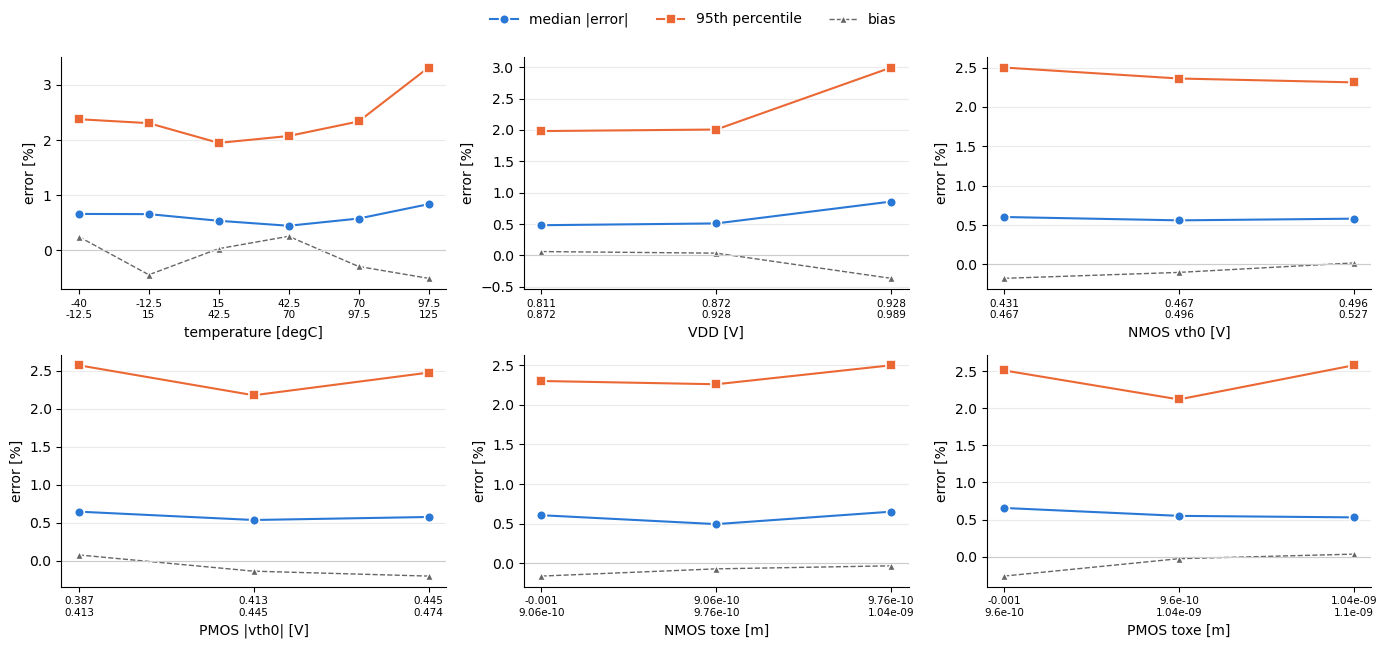

In [4]:
COL = {"median": "#2a78d6", "p95": "#eb6834"}
fig, ax = plt.subplots(2, 3, figsize=(14, 6.5))
for a, (name, t) in zip(ax.ravel(), tabs.items()):
    x = np.arange(len(t))
    a.plot(x, t["median [%]"], "o-", color=COL["median"], ms=7, mec="white", mew=1.2, label="median |error|")
    a.plot(x, t["95th pct [%]"], "s-", color=COL["p95"], ms=7, mec="white", mew=1.2, label="95th percentile")
    a.plot(x, t["bias [%]"], "^--", color="0.4", ms=6, mec="white", mew=1.0, lw=1, label="bias")
    a.axhline(0, color="0.8", lw=0.8)
    a.set_xticks(x); a.set_xticklabels([s.replace(" .. ", "\n") for s in t.index], fontsize=7.5)
    a.set_xlabel(name); a.set_ylabel("error [%]")
    a.grid(axis="y", color="0.92", lw=0.8); a.set_axisbelow(True); a.spines[["top", "right"]].set_visible(False)
handles, labels = ax[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(RESULT_DIR / "gate_error_factors.png", dpi=110)
plt.show()

## 4. Gate level: which transistor model and which leakage component
The leakage of a gate is the sum of the terms of its transistors (channel, gate, body; notebook 05). With the same voltages, the transistor currents from the ML models and from SPICE give two values of every term, so the error of the gate leakage can be traced back to a model and a component: for each combination, `sum |ML - SPICE| / sum(gate leakage)` over all 3,600 operating points (the **absolute error budget**, in %), and the same with signs (the **bias**; the sum of the signed terms is the total bias of the table above).

In [5]:
dv = dev.merge(gate[KEY + ["leak_total"]], on=KEY)
total = gate["leak_total"].sum()
rows = []
for case, g in dv.groupby("case"):
    for comp in ("channel", "gate", "body"):
        d = g[f"ml_{comp}"] - g[f"spice_{comp}"]
        rows.append(dict(model=case, component=comp, abs_budget=d.abs().sum() / total * 100, bias=d.sum() / total * 100, n=len(g)))
budget = pd.DataFrame(rows)
budget_abs = budget.pivot(index="model", columns="component", values="abs_budget").assign(total=lambda t: t.sum(axis=1))
budget_bias = budget.pivot(index="model", columns="component", values="bias").assign(total=lambda t: t.sum(axis=1))
pd.concat({"absolute error budget [% of the summed leakage]": budget_abs, "bias [% of the summed leakage]": budget_bias}, axis=1).to_csv(RESULT_DIR / "gate_error_budget.csv")
display(budget_abs.round(2).rename_axis("absolute error budget [% of the summed leakage]"))
display(budget_bias.round(2).rename_axis("bias [% of the summed leakage]"))
print("check: summed bias of all terms =", round(budget["bias"].sum(), 3), "% | bias of the sum of the gate leakages =", round((gate["ml_leak"].sum() - total) / total * 100, 3), "%")

component,body,channel,gate,total
absolute error budget [% of the summed leakage],,,,
nmos_off,0.0,0.34,0.0,0.34
nmos_on,0.0,0.02,0.0,0.02
pmos_off,0.0,1.06,0.0,1.06
pmos_on,0.0,0.01,0.0,0.01


component,body,channel,gate,total
bias [% of the summed leakage],,,,
nmos_off,0.0,-0.22,-0.0,-0.22
nmos_on,0.0,0.01,-0.0,0.01
pmos_off,0.0,-0.07,-0.0,-0.07
pmos_on,0.0,0.00,0.0,0.00


check: summed bias of all terms = -0.272 % | bias of the sum of the gate leakages = -0.272 %


**Share of the SPICE leakage by term** (how much each model / component contributes to the leakage itself, to read the budget against):

In [6]:
share = pd.DataFrame([dict(model=case, component=comp, share=g[f"spice_{comp}"].sum() / total * 100) for case, g in dv.groupby("case") for comp in ("channel", "gate", "body")])
share = share.pivot(index="model", columns="component", values="share").assign(total=lambda t: t.sum(axis=1))
share.to_csv(RESULT_DIR / "gate_leakage_share.csv")
share.round(1)

component,body,channel,gate,total
model,,,,
nmos_off,0.0,20.4,0.0,20.4
nmos_on,0.0,0.9,0.1,1.0
pmos_off,0.0,77.8,0.0,77.8
pmos_on,0.0,0.8,0.0,0.9


## 5. The ten worst gate operating points

In [7]:
worst = gate.reindex(gate["err"].abs().sort_values(ascending=False).index).head(10)[KEY + ["temp", "vdd", "n_vth0", "p_vth0", "leak_total", "ml_leak", "err"]].copy()
dom = []
for _, r in worst.iterrows():
    g = dv[(dv.gate == r.gate) & (dv.pattern == r.pattern) & (dv.corner == r.corner)]
    best = max(((abs(row[f"ml_{c}"] - row[f"spice_{c}"]), f"{row['device']} ({row['case']}) {c}") for _, row in g.iterrows() for c in ("channel", "gate", "body")))
    dom.append(best[1])
worst["largest term error"] = dom
worst.to_csv(RESULT_DIR / "gate_worst_points.csv", index=False)
worst.assign(err=lambda t: (t["err"] * 100).round(1), leak_total=lambda t: t["leak_total"].map("{:.2e}".format), ml_leak=lambda t: t["ml_leak"].map("{:.2e}".format))

,gate,pattern,corner,temp,vdd,n_vth0,p_vth0,leak_total,ml_leak,err,largest term error
2233,and2,01,58,122.268226,0.965338,0.442852,-0.463980,1.94e-06,1.77e-06,-8.4,MP3 (pmos_off) channel
3032,or2,00,58,122.268226,0.965338,0.442852,-0.463980,1.88e-06,1.72e-06,-8.1,MP3 (pmos_off) channel
2017,and2,01,4,104.608766,0.983688,0.471816,-0.434457,1.73e-06,1.59e-06,-7.6,MP3 (pmos_off) channel
2816,or2,00,4,104.608766,0.983688,0.471816,-0.434457,1.64e-06,1.53e-06,-7.0,MP3 (pmos_off) channel
2609,and2,01,152,109.657748,0.927274,0.474755,-0.448647,1.06e-06,9.90e-07,-6.5,MP3 (pmos_off) channel
3408,or2,00,152,109.657748,0.927274,0.474755,-0.448647,9.88e-07,9.30e-07,-5.9,MP3 (pmos_off) channel
3033,or2,01,58,122.268226,0.965338,0.442852,-0.463980,1.64e-06,1.56e-06,-5.4,MN3 (nmos_off) channel
282,inv,0,141,-3.781392,0.980123,0.482198,-0.428340,1.02e-07,9.68e-08,-5.3,MN1 (nmos_off) channel
3367,or2,11,141,-3.781392,0.980123,0.482198,-0.428340,1.03e-07,9.71e-08,-5.3,MN3 (nmos_off) channel
1764,nor2,00,141,-3.781392,0.980123,0.482198,-0.428340,2.04e-07,1.93e-07,-5.3,MN2 (nmos_off) channel


## 6. Gate level: inputs of the inverter inside AND2 and OR2 that are not at a rail
The transistor models were trained with the gate voltage at exactly 0 or VDD, and the gate voltage of a transistor is set to the nearest rail when the models are called (as in the instructor's AND2 equation). In AND2 and OR2 the inverter is driven by the NAND2 / NOR2 output, which in SPICE sits a few millivolts away from its rail (leakage through the ON network). The table gives, for each of the eight AND2 / OR2 cases, the distance of that node from the rail it should be at, and the rank correlation (Spearman) between this distance and the signed error of the gate leakage over the 200 corners, and between the distance and the temperature and the VDD of the corner.

In [8]:
def inv_input_rail(g, p):                         # logic value of the NAND2 / NOR2 output that drives the inverter: 1 -> VDD, 0 -> 0 V
    return (p != "11") if g == "and2" else (p == "00")


rows = []
for (g, p), d in gate[gate.gate.isin(["and2", "or2"])].groupby(["gate", "pattern"], sort=False):
    dist = (d["vdd"] - d["v_n"]) if inv_input_rail(g, p) else d["v_n"]
    rows.append({"gate": g, "pattern": p, "rail": "VDD" if inv_input_rail(g, p) else "0 V", "median distance [mV]": dist.median() * 1e3, "max distance [mV]": dist.max() * 1e3,
                 "Spearman(distance, error)": dist.corr(d["err"], method="spearman"), "Spearman(distance, temperature)": dist.corr(d["temp"], method="spearman"), "Spearman(distance, VDD)": dist.corr(d["vdd"], method="spearman"), "median signed error [%]": d["err"].median() * 100, "median |error| [%]": d["err"].abs().median() * 100})
nonrail = pd.DataFrame(rows)
nonrail.to_csv(RESULT_DIR / "gate_error_nonrail_input.csv", index=False)
nonrail.round(2)

,gate,pattern,rail,median distance [mV],max distance [mV],"Spearman(distance, error)","Spearman(distance, temperature)","Spearman(distance, VDD)",median signed error [%],median |error| [%]
0,and2,00,VDD,0.00,0.07,0.06,0.89,-0.07,0.29,0.59
1,and2,01,VDD,1.42,19.54,-0.68,0.80,0.15,-0.72,0.90
2,and2,10,VDD,0.19,3.81,-0.28,0.84,0.04,0.01,0.58
3,and2,11,0 V,3.99,29.18,-0.19,0.56,0.43,-0.23,0.66
4,or2,00,VDD,1.09,17.60,-0.61,0.80,0.15,-0.68,0.89
5,or2,01,0 V,4.28,25.50,-0.32,0.58,0.42,-0.02,0.71
6,or2,10,0 V,0.43,2.78,-0.28,0.71,0.21,-0.35,0.47
7,or2,11,0 V,0.00,0.04,0.15,0.87,0.01,-0.28,0.49


## 7. Test circuit
The error of the hierarchical prediction is the sum of two parts: the **composition floor** (the sum of the isolated-gate SPICE leakages against the full-circuit SPICE leakage, i.e. what perfect gate models would give: loading and non-ideal gate inputs) and the **gate-model error** (ML gate leakage against the isolated-gate SPICE sum). Both by corner condition:

In [9]:
rows = []
for col, name, bins in FACTORS[:4]:
    cut = pd.cut(circ[col], bins, include_lowest=True) if isinstance(bins, list) else pd.qcut(circ[col], bins)
    for iv, g in circ.groupby(cut, observed=True):
        rows.append({"factor": name, "bin": f"{iv.left:.3g} .. {iv.right:.3g}",
                     "ML: median |err| [%]": g["err"].abs().median() * 100, "ML: 95th pct [%]": g["err"].abs().quantile(0.95) * 100, "ML: bias [%]": g["err"].mean() * 100,
                     "floor: median |err| [%]": g["err_floor"].abs().median() * 100, "floor: bias [%]": g["err_floor"].mean() * 100,
                     "gate models: bias [%]": g["err_gates"].mean() * 100, "gate models: median |err| [%]": g["err_gates"].abs().median() * 100})
circ_tab = pd.DataFrame(rows).set_index(["factor", "bin"])
circ_tab.to_csv(RESULT_DIR / "circuit_error_by_corner.csv")
circ_tab.round(2)

ML: median |err| [%]  ML: 95th pct [%]  ML: bias [%]  floor: median |err| [%]  floor: bias [%]  gate models: bias [%]  gate models: median |err| [%]
factor             bin                                                                                                                                                                 
temperature [degC] -40 .. -12.5                    0.60              2.74         -0.19                     0.40            -0.55                   0.36                           0.45
                   -12.5 .. 15                     1.26              3.81         -1.35                     0.78            -0.96                  -0.39                           0.68
                   15 .. 42.5                      1.35              2.90         -1.22                     1.21            -1.38                   0.16                           0.41
                   42.5 .. 70                      1.10              3.58         -1.27                     1.31            -1.65                   0.39                           0.34
                   70 .. 97.5                      2.46              7.25         -3.05                     2.31            -2.76                  -0.30                           0.46
                   97.5 .. 125                     3.87              9.88         -4.52                     3.42            -3.91                  -0.64                           0.86
VDD [V]            0.811 .. 0.872                  0.99              3.97         -1.13                     0.97            -1.28                   0.15                           0.36
                   0.872 .. 0.928                  1.57              4.51         -1.80                     1.54            -1.82                   0.02                           0.38
                   0.928 .. 0.989                  2.13              8.47         -2.71                     1.82            -2.46                  -0.27                           0.88
NMOS vth0 [V]      0.431 .. 0.467                  2.24              7.96         -2.83                     2.21            -2.66                  -0.18                           0.45
                   0.467 .. 0.496                  1.48              5.37         -1.84                     1.43            -1.80                  -0.04                           0.58
                   0.496 .. 0.527                  1.00              3.51         -0.95                     0.85            -1.08                   0.13                           0.42
PMOS |vth0| [V]    0.387 .. 0.413                  1.36              5.37         -1.63                     1.54            -1.92                   0.30                           0.46
                   0.413 .. 0.445                  1.91              6.15         -2.18                     1.62            -1.99                  -0.20                           0.44
                   0.445 .. 0.474                  1.27              7.14         -1.82                     1.10            -1.63                  -0.19                           0.54

**By input vector** (200 corners each): the vectors with the largest and smallest median error of the hierarchical prediction.

In [10]:
bv = circ.groupby("vector").apply(lambda g: pd.Series({"a": int(g.name) & 7, "b": (int(g.name) >> 3) & 7, "cin": int(g.name) >> 6, "median |err| [%]": g["err"].abs().median() * 100,
                                                       "bias [%]": g["err"].mean() * 100, "SPICE median [A]": g["leak_total"].median()}), include_groups=False)
print("largest median error:")
display(bv.sort_values("median |err| [%]", ascending=False).head(6).round(3))
print("smallest median error:")
bv.to_csv(RESULT_DIR / "circuit_error_by_vector.csv")
bv.sort_values("median |err| [%]").head(6).round(3)

largest median error:


,a,b,cin,median |err| [%],bias [%],SPICE median [A]
vector,,,,,,
64,0.0,0.0,1.0,2.099,-2.546,0.0
66,2.0,0.0,1.0,2.054,-2.489,0.0
68,4.0,0.0,1.0,2.053,-2.487,0.0
73,1.0,1.0,1.0,2.045,-2.484,0.0
82,2.0,2.0,1.0,2.023,-2.458,0.0
70,6.0,0.0,1.0,2.002,-2.433,0.0


smallest median error:


,a,b,cin,median |err| [%],bias [%],SPICE median [A]
vector,,,,,,
57,1.0,7.0,0.0,1.036,-1.136,0.0
120,0.0,7.0,1.0,1.047,-1.164,0.0
92,4.0,3.0,1.0,1.165,-1.319,0.0
106,2.0,5.0,1.0,1.165,-1.321,0.0
124,4.0,7.0,1.0,1.172,-1.302,0.0
122,2.0,7.0,1.0,1.174,-1.346,0.0


## Summary of the error analysis
* **Gate level, gate and input pattern:** the least accurate cases are AND2 01 (median 0.90 %, 95th percentile 3.63 %, bias -0.93 %) and OR2 00 (0.89 %, 3.81 %, -0.93 %), the most accurate NAND2 01 (0.35 %); every case has a median error below 1 %.
* **Corner conditions:** the error is largest at the hot end (97.5 to 125 degC: median 0.84 %, 95th percentile 3.31 %, against 0.45 to 0.66 % in the other temperature bins) and in the highest VDD tercile (0.86 % against 0.48 % and 0.51 %); `vth0` and `toxe` of the NMOS and the PMOS show no consistent trend (0.50 to 0.66 %).
* **Error budget:** the channel terms of the two OFF models are almost the whole error: PMOS OFF about three quarters (1.06 of 1.43 percentage points), NMOS OFF about a quarter; the OFF transistors carry 98 % of the leakage; the gate and body terms contribute less than 0.01 points, and the ON models about 0.03 points.
* **Worst points:** all ten are underestimates of 5.3 % to 8.4 %; six are AND2 01 / OR2 00 at hot, high-VDD corners, where the PMOS-OFF channel term of the inverter dominates. The inverter input is a few millivolts from its rail in SPICE (median 1.4 mV, up to 19.5 mV in AND2 01) but is set to the rail when the models are called; the distance correlates with the error (Spearman -0.68 for AND2 01, -0.61 for OR2 00) and grows with temperature (Spearman 0.80).
* **Test circuit:** the median error of the hierarchical prediction rises from 0.60 % (-40 to -12.5 degC) to 3.87 % (97.5 to 125 degC); the composition floor follows it (0.40 % to 3.42 %), while the error of the ML gate models stays at 0.34 % to 0.86 %. The error depends little on the input vector (1.04 % to 2.10 % median per vector).